# Detecção e classificação de crimes cibernéticos em redes sociais utilizando algoritmos de aprendizado de máquina

**Alunos:**

Caio Vinícius Cunha Bernardo - *Nro. USP: 14652143*

Lucas Neves Souza - *Nro. USP: 15577627*

Willian Jefferson Sousa Farias - *Nro. USP: 15642665*

---

## Notebook 1 de 3: dataset de dois rótulos (Binary)

Reúne a **análise exploratória** e o **modelo em cascata** (Fase 1: SVM com TF-IDF; Fase 2: BERTimbau) para o dataset de dois rótulos.

**Projeto em três notebooks**

1. `1_Dois_Rotulos.ipynb` **(este notebook)**: análise exploratória e cascata (SVM + BERTimbau) no dataset **Binary** (`aggressive`, `hate`).
2. `2_Treze_Rotulos.ipynb`: análise exploratória e cascata no dataset **Multilabel** (13 rótulos), com ROC-AUC, matrizes de confusão, atenção e ablação da perda ponderada.
3. `3_Simulacao_Oliveira.ipynb`: baselines de estágio único para reproduzir os resultados de Oliveira et al. (2024) e compará-los com a cascata.

Os notebooks 1 e 2 gravam os resultados da cascata na pasta `resultados/`, que o notebook 3 lê para as comparações. Rode na ordem 1 → 2 → 3; o notebook 3 também roda sozinho, e nesse caso as comparações com a cascata são ignoradas.

A intensa conectividade fornecida pelas redes sociais, através da internet, revolucionou a maneira a qual interagimos com as pessoas, possibilitando diferentes níveis de comunicação.

Entretanto, essa disrupção também abriu as portas para distintas formas de desrespeito e ataques morais, gerando o que chamamos de discurso de ódio. A linguagem inerente a esse tipo de ataque possui padrões e, para cada cenário, o tipo de crime pode variar.

O discurso de ódio pode envolver, por exemplo, racismo, misoginia, homofobia, etc. No caso, podem estar presentes um ou mais desses "arquétipos" em uma única mensagem.

Neste projeto, nosso objetivo é estruturar um modelo capaz de:

1) Detectar esses crimes através de processamento de língua natural;

2) Classificá-los em diferentes categorias.

# Setup

Primeiramente, realizamos a instalação das bibliotecas pelo terminal. Vamos instalar a biblioteca do **Hugging Face** (transformers), os *datasets* do Hugging Face e a ferramenta de otimização (accelerate), exigida pelo `Trainer`. As demais bibliotecas (pandas, scikit-learn, PyTorch, matplotlib, seaborn) já vêm instaladas no Google Colab.

1) Hugging Face: plataforma open-source onde desenvolvedores compartilham e colaboram em modelos de aprendizado de máquina, *datasets* e outras ferramentas de IA.

In [1]:
!pip install -q transformers accelerate datasets

Vamos importar as bibliotecas necessárias para a nossa programação:

1) O **pandas** é uma biblioteca de código aberto para a linguagem Python focada em manipulação e análise de dados;
2) O **Scikit-learn** (também conhecido como sklearn) é uma biblioteca de código aberto para a linguagem Python voltada para o aprendizado de máquina e modelagem estatística (Fase 1: TF-IDF + SVM);
3) O **PyTorch** é uma biblioteca usada principalmente para inteligência artificial, aprendizado de máquina e aprendizado profundo;
4) **matplotlib** e **seaborn** serão usadas na Análise Exploratória.

Embora o pandas seja excelente para manipular planilhas e visualizar os textos, os modelos de rede neural pesada processam dados em blocos vetoriais (Tensores). A biblioteca **datasets** converte DataFrames do Pandas para um formato de memória que a GPU consegue consumir muito mais rápido.

Além disso, no Deep Learning, o treinamento ocorre em épocas, exige cálculo de perda, ajuste na taxa de aprendizado e controle do tamanho do lote. As classes **Trainer** e **TrainingArguments** abstraem toda essa engenharia para que possamos treinar o BERT usando poucas linhas.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from datasets import Dataset

# Fase 1 (Scikit-learn)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split

# Fase 2 (Hugging Face e PyTorch)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
set_seed(SEED)

# Verificar se a GPU foi reconhecida pelo PyTorch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Processamento rodando em: {device}")

Processamento rodando em: cuda


O fluxo final será: o **Scikit-learn** faz a triagem inicial (Fase 1: há ou não crime), o **pandas** e o **Dataset** organizam os textos, e o **Trainer** ajusta os pesos do modelo **BERT** para classificar as categorias (Fase 2).

Por fim, definimos o modelo pré-treinado (BERTimbau, versão *base*, mais leve que a *large*) e carregamos seu *tokenizer*, que será usado na Fase 2:

In [3]:
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer_bert = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

# Importando Dataset pelo GitHub

Vamos fazer a importação dos arquivos **.csv** do [repositório original](https://github.com/Silly-Machine/TuPyE-Expanded-Brazilian-Hate-Speech-Dataset).

In [4]:
# Colunas que não serão úteis para o treinamento (rede social, pesquisador e ano)
COLUNAS_DESCARTADAS = ['source', 'researcher', 'year']

BASE_URL = ("https://raw.githubusercontent.com/Silly-Machine/"
            "TuPyE-Expanded-Brazilian-Hate-Speech-Dataset/refs/heads/master")

# Binary
df_binary_train = pd.read_csv(f"{BASE_URL}/binary/binary_train.csv")
df_binary_test = pd.read_csv(f"{BASE_URL}/binary/binary_test.csv")

Vamos unificar as duas partes (treino e teste) do dataset para realizarmos a **análise exploratória**:

In [5]:
# ignore_index=True evita índices duplicados (treino e teste ambos começam em 0)
df_binary_full = pd.concat([df_binary_train, df_binary_test], ignore_index=True)

# Análise Exploratória do Dataset Binary

Primeiramente, vamos analisar as cinco primeiras linhas:

In [6]:
df_binary_full.head()

,source,text,researcher,year,aggressive,hate
0,twitter,rt @user quero mais aaaaaa,leite et al,2020,0,0
1,twitter,@user @user fala não porra 🤦🏾‍♀️,leite et al,2020,0,0
2,instagram,Cadeia aos racistas!,vargas et al,2021,0,0
3,instagram,"Obrigado deputada, continue defendendo nossa c...",vargas et al,2021,0,0
4,instagram,Milícias digitais e reais! Fazem um grande est...,vargas et al,2021,1,0


Como a referência a respeito da rede social de origem (source), aos pesquisadores responsáveis por cada dado e rotulações (researcher) e o ano de coleta (year) não serão úteis para o treinamento do modelo, começaremos os ajustes no DataFrame a partir da remoção dessas colunas.

In [7]:
# Realizando a retirada das colunas "source", "researcher" e "year"
df_binary_cleaned = df_binary_full.drop(columns=COLUNAS_DESCARTADAS)
df_binary_cleaned.head()

,text,aggressive,hate
0,rt @user quero mais aaaaaa,0,0
1,@user @user fala não porra 🤦🏾‍♀️,0,0
2,Cadeia aos racistas!,0,0
3,"Obrigado deputada, continue defendendo nossa c...",0,0
4,Milícias digitais e reais! Fazem um grande est...,1,0


Agora, para termos uma noção do valor absoluto de textos agressivos e de ódio, vamos imprimir a frequência absoluta de cada rótulo:

aggressive    11273
hate           5253
dtype: int64


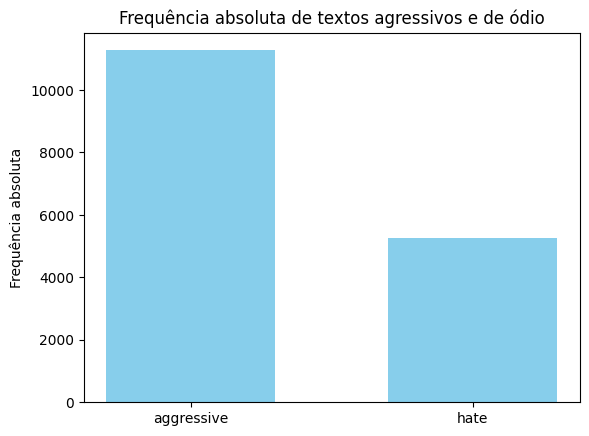

In [8]:
# O texto, aqui, não será útil
df_binary_frequency = df_binary_cleaned.drop(columns='text')

# Realizando somatório para cada coluna
col_sum_binary = df_binary_frequency.sum()

print(col_sum_binary)

# Em formato de gráfico de barras vertical:
plt.bar(col_sum_binary.index.tolist(), col_sum_binary.values, color='skyblue', width=0.6)
plt.ylabel('Frequência absoluta')
plt.title('Frequência absoluta de textos agressivos e de ódio')
plt.show()

O gráfico de frequência absoluta acima já mostra que os rótulos "aggressive" e
"hate" são pouco frequentes no dataset, mas os valores absolutos escondem a real
proporção do desbalanceamento. Vamos visualizar isso em termos percentuais:

aggressive    25.815242
hate          12.029404
dtype: float64


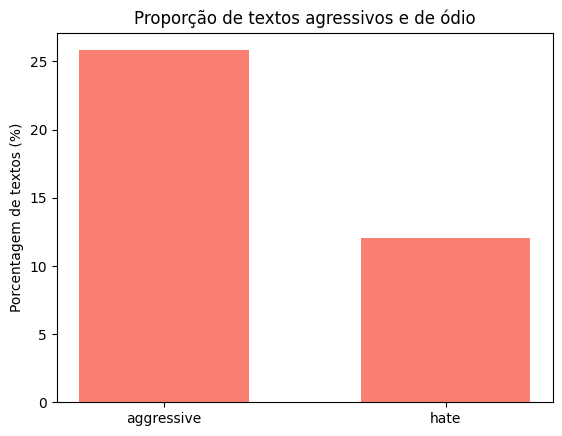

In [9]:
# Proporção percentual de cada rótulo

total_binary = len(df_binary_cleaned)
percent_binary = (col_sum_binary / total_binary) * 100

print(percent_binary)

plt.bar(percent_binary.index.tolist(), percent_binary.values, color='salmon', width=0.6)
plt.ylabel('Porcentagem de textos (%)')
plt.title('Proporção de textos agressivos e de ódio')
plt.show()

Como era esperado, ambas as classes
representam uma pequena minoria do total de mensagens, o que confirma, já nesta
fase exploratória, a necessidade do tratamento de desbalanceamento previsto na metodologia
para o SVM da Fase 1 (ponderação de classes com `class_weight='balanced'`,
além da margem suave controlada pelo parâmetro C).

## Relação entre os rótulos "aggressive" e "hate"

Diferentemente de datasets com um único rótulo binário de ódio/não-ódio, o
dataset Binary aqui utilizado possui dois rótulos distintos e não excludentes.
É importante entender a sobreposição entre eles antes de definirmos o que será,
de fato, a "tendência maliciosa" que o SVM da Fase 1 irá detectar: será hate,
aggressive, ou a união dos dois? Para responder a isso, construímos uma tabela
de contingência (crosstab) entre os dois rótulos:

hate            0     1
aggressive             
0           32395     0
1            6020  5253


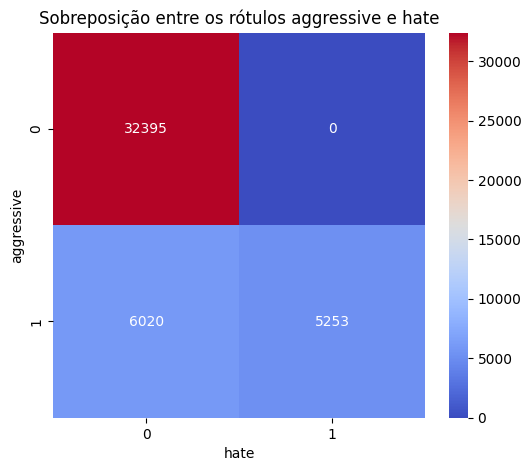

In [10]:
# Crosstab entre aggressive e hate

crosstab_binary = pd.crosstab(df_binary_cleaned['aggressive'], df_binary_cleaned['hate'])
print(crosstab_binary)

plt.figure(figsize=(6, 5))
sns.heatmap(crosstab_binary, annot=True, fmt='d', cmap='coolwarm')
plt.xlabel('hate')
plt.ylabel('aggressive')
plt.title('Sobreposição entre os rótulos aggressive e hate')
plt.show()

O gráfico do mapa de calor acima revela um padrão de que não existe nenhum
caso de "hate" sem "aggressive" (a célula aggressive=0/hate=1 é igual a zero), ou seja, todo texto marcado como discurso de ódio neste dataset também foi
marcado como agressivo. Já entre os textos agressivos, 6.020 não são de ódio,
contra 5.253 que carregam os dois rótulos simultaneamente. Isso mostra que nem todo texto agressivo é odioso, mas todo texto odioso é agressivo.

Esse fato é diretamente relevante para a definição do alvo de treinamento da Fase 1, em que definir a "tendência maliciosa" como a união (OR) dos dois rótulos (aggressive OR hate) captura tanto os casos de agressividade "pura" quanto os de discurso de ódio propriamente dito, evitando que mensagens agressivas, mas não caracterizadas como ódio, sejam descartadas já na triagem inicial da Fase 1.

## Quantidade de rótulos maliciosos por mensagem

Também é válido observar quantos rótulos maliciosos (0, 1 ou 2) cada mensagem recebeu simultaneamente:

0    32395
1     6020
2     5253
Name: count, dtype: int64


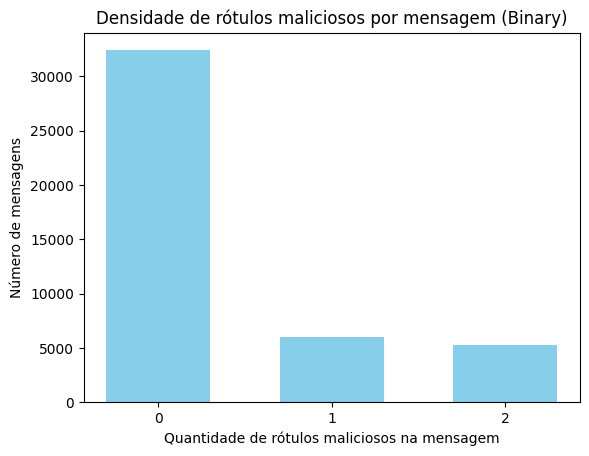

In [11]:
# Densidade de rótulos maliciosos por mensagem (0, 1 ou 2)
line_sum_binary = df_binary_frequency.sum(axis=1)
contagem_rotulos_binary = line_sum_binary.value_counts().sort_index()
print(contagem_rotulos_binary)

plt.bar(contagem_rotulos_binary.index.astype(str), contagem_rotulos_binary.values,
        color='skyblue', width=0.6)
plt.xlabel('Quantidade de rótulos maliciosos na mensagem')
plt.ylabel('Número de mensagens')
plt.title('Densidade de rótulos maliciosos por mensagem (Binary)')
plt.show()

Chama atenção que a simultaneidade dos dois rótulos (valor 2) não é um caso raro entre os textos maliciosos: ela corresponde a praticamente metade (46,6%) das mensagens que carregam ao menos um rótulo, reforçando visualmente o desbalanceamento identificado na análise anterior.

## Distribuição do tamanho dos textos (Dataset Binary)

Por fim, vale observar a distribuição do tamanho dos textos (em número de
caracteres) do dataset Binary. Essa distribuição orienta decisões de
pré-processamento, como o tamanho de corte (truncamento) a ser usado tanto na
vetorização TF-IDF da Fase 1 quanto, futuramente, no tokenizer do BERT na
Fase 2:

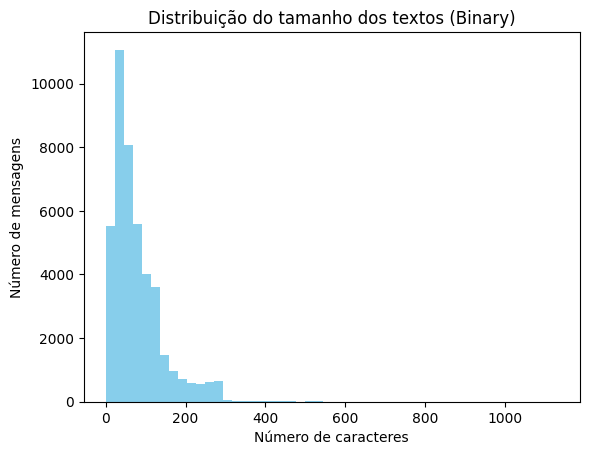

,text
count,43668.000000
mean,78.701292
std,64.432013
min,1.000000
25%,34.000000
50%,60.000000
75%,105.000000
max,1131.000000


In [12]:
# Distribuição do tamanho dos textos
char_count_binary = df_binary_cleaned['text'].str.len()

plt.hist(char_count_binary, bins=50, color='skyblue')
plt.xlabel('Número de caracteres')
plt.ylabel('Número de mensagens')
plt.title('Distribuição do tamanho dos textos (Binary)')
plt.show()

char_count_binary.describe()

A distribuição confirma que as mensagens do dataset Binary são predominantemente curtas: a média é de aproximadamente 79 caracteres, com
mediana de 60 e desvio padrão de cerca de 64,4, o que é coerente com a origem dos dados, majoritariamente extraídos de Twitter e Instagram. Metade dos textos
tem até 60 caracteres e 75% não ultrapassam 105 caracteres, embora existam
*outliers* (o maior texto do dataset tem 1.131 caracteres).

Como mensagens de ~105 caracteres costumam gerar poucas dezenas de *tokens*, um `max_length` de 128 *tokens* no tokenizer do BERT (Fase 2) já preserva a quase totalidade do conteúdo semântico da grande maioria das mensagens, truncando apenas os *outliers* mais longos, sem custo computacional desnecessário.

# Desenvolvimento do Modelo para Dois Rótulos

### Começando pela fase de "peneira" (tem ou não tem crime)

In [13]:
df_binary_train_cleaned = df_binary_train.drop(columns=COLUNAS_DESCARTADAS)
df_binary_test_cleaned = df_binary_test.drop(columns=COLUNAS_DESCARTADAS)

# Colunas que representam as infrações (ignorando a coluna 'text')
colunas_crimes = ['aggressive', 'hate']

# Coluna 'label' (exigida pelo Hugging Face): .max(axis=1) varre a linha
# horizontalmente; se encontrar algum 1, o label vira 1 (aggressive OR hate).
df_binary_train_cleaned['label'] = df_binary_train_cleaned[colunas_crimes].max(axis=1)
df_binary_test_cleaned['label'] = df_binary_test_cleaned[colunas_crimes].max(axis=1)

X_train = df_binary_train_cleaned['text']
y_train = df_binary_train_cleaned['label']
X_test = df_binary_test_cleaned['text']
y_test = df_binary_test_cleaned['label']

In [14]:
# 1. Pipeline para redes sociais
pipeline_svm_otimizado = Pipeline([
    # Combinação de N-gramas de palavras e poda de ruído
    ('tfidf', TfidfVectorizer(
        max_features=20000,
        analyzer='word',      # Pode testar 'char_wb' se a ofuscação for severa
        ngram_range=(1, 3),   # Captura expressões curtas (ex: "filho da p...")
        min_df=3,             # Poda termos raros (ruído)
        max_df=0.85           # Poda termos ubíquos (excesso)
    )),

    # LinearSVC com margem suavizada (C=0.5) envolto no calibrador de probabilidades
    ('classificador_calibrado', CalibratedClassifierCV(
        estimator=LinearSVC(C=0.5, class_weight='balanced', random_state=SEED, max_iter=3000),
        method='isotonic',
        cv=5                  # Validação cruzada interna para calibrar as probabilidades
    ))
])

# 2. Validação (15% do treino) para escolher o limiar
df_sub, df_val = train_test_split(df_binary_train_cleaned, test_size=0.15,
                                  stratify=df_binary_train_cleaned['label'], random_state=SEED)
print("Treinando o filtro SVM na parte de treino (85%)...")
pipeline_svm_otimizado.fit(df_sub['text'], df_sub['label'])
p_val = pipeline_svm_otimizado.predict_proba(df_val['text'])[:, 1]

# Maior limiar que ainda mantém revocação >= alvo na VALIDAÇÃO
alvo = 0.90
pos = (df_val['label'].values == 1)
candidatos = [t for t in np.arange(0.05, 0.60, 0.01)
              if ((p_val >= t) & pos).sum() / pos.sum() >= alvo]
if not candidatos:
    print("⚠️ Nenhum limiar atingiu a revocação-alvo na validação; usando o mínimo da grade.")
limiar_svm_calibrado = max(candidatos) if candidatos else 0.05
print(f"Limiar escolhido na validação: {limiar_svm_calibrado:.2f}")

# 3. Reajuste no treino completo e predição no teste (usado uma única vez)
print("Reajustando o filtro SVM no treino completo...")
pipeline_svm_otimizado.fit(X_train, y_train)
probabilidade_crime_svm = pipeline_svm_otimizado.predict_proba(X_test)[:, 1]
y_pred_svm_otimizado = (probabilidade_crime_svm >= limiar_svm_calibrado).astype(int)

# 4. Avaliação
print(f"\nRelatório SVM (limiar de probabilidade: {limiar_svm_calibrado:.2f}):")
print(classification_report(y_test, y_pred_svm_otimizado, target_names=["Benigno", "Crime"]))

Treinando o filtro SVM na parte de treino (85%)...
Limiar escolhido na validação: 0.12
Reajustando o filtro SVM no treino completo...

Relatório SVM (limiar de probabilidade: 0.12):
              precision    recall  f1-score   support

     Benigno       0.94      0.49      0.64      6447
       Crime       0.39      0.91      0.54      2287

    accuracy                           0.60      8734
   macro avg       0.66      0.70      0.59      8734
weighted avg       0.79      0.60      0.61      8734



> **Protocolo de validação.** 15% do conjunto de treino (estratificado pelo rótulo da Fase 1) é separado como **validação**. O SVM é treinado nos 85% restantes, e o limiar de decisão é o maior valor que mantém revocação de pelo menos 0,90 na validação. Em seguida, o SVM é reajustado no treino completo (o limiar foi escolhido no modelo de 85% e aplicado ao modelo reajustado). O conjunto de **teste** é usado uma única vez, na avaliação final.

### Classificação das duas categorias, pós-filtro

Na Fase 2, o BERTimbau recebe apenas o que o SVM deixou passar. Para que a rede não superestime a presença de crimes por nunca ver exemplos benignos durante o ajuste fino ("visão de túnel"), o **treino** reúne todos os crimes reais mais uma amostra aleatória de textos benignos do mesmo tamanho (proporção 1:1). O **teste** mantém a lógica do fluxo em cascata: todos os textos aprovados pelo SVM, sejam crimes reais ou falsos positivos.

A **validação** (usada para escolher a melhor época do BERT) segue a mesma lógica do teste: são os textos reservados do treino que o SVM deixou passar. O BERT é treinado apenas com os 85% restantes do treino.

In [15]:
# 1. Separar as duas classes no conjunto de TREINO (já sem os 15% reservados para validação)
df_crimes_treino = df_sub[df_sub['label'] == 1]
df_benignos_treino = df_sub[df_sub['label'] == 0]

# 2. Amostra aleatória de benignos do exato tamanho dos crimes (proporção 1:1)
df_benignos_amostra = df_benignos_treino.sample(n=len(df_crimes_treino), random_state=SEED)

# 3. Mesclar e embaralhar o conjunto de treino da Fase 2
df_fase2_train = pd.concat([df_crimes_treino, df_benignos_amostra]).sample(frac=1, random_state=SEED).copy()

# Validação: textos de validação que o SVM (treinado em 85%) deixou passar
df_fase2_val = df_val[p_val >= limiar_svm_calibrado].copy()

# Teste: tudo o que o SVM deixou passar (usado uma única vez, na avaliação final)
indices_suspeitos_teste = (y_pred_svm_otimizado == 1)
df_fase2_test = df_binary_test_cleaned[indices_suspeitos_teste].copy()

print(f"Textos para treino (crimes + benignos amostrados): {len(df_fase2_train)}")
print(f"Textos para validação (aprovados pelo SVM): {len(df_fase2_val)}")
print(f"Textos para teste (aprovados pelo SVM): {len(df_fase2_test)}")

# Rótulos multirrótulo (lista de floats): benigno = vetor de zeros
for d in (df_fase2_train, df_fase2_val, df_fase2_test):
    d['labels'] = d[colunas_crimes].values.astype(float).tolist()

Textos para treino (crimes + benignos amostrados): 15276
Textos para validação (aprovados pelo SVM): 3293
Textos para teste (aprovados pelo SVM): 5396


In [16]:
# O BERT usa a coluna 'text' bruta (com pontuação e conectivos).
# O padding é feito dinamicamente por lote (DataCollatorWithPadding),
# em vez de preencher todos os textos até max_length.
def tokenizar(exemplos):
    return tokenizer_bert(exemplos['text'], truncation=True, max_length=128)

dataset_fase2_train = Dataset.from_pandas(df_fase2_train[['text', 'labels']], preserve_index=False)
dataset_fase2_val = Dataset.from_pandas(df_fase2_val[['text', 'labels']], preserve_index=False)
dataset_fase2_test = Dataset.from_pandas(df_fase2_test[['text', 'labels']], preserve_index=False)

dataset_fase2_train = dataset_fase2_train.map(tokenizar, batched=True)
dataset_fase2_val = dataset_fase2_val.map(tokenizar, batched=True)
dataset_fase2_test = dataset_fase2_test.map(tokenizar, batched=True)

Map:   0%|          | 0/15276 [00:00<?, ? examples/s]

Map:   0%|          | 0/3293 [00:00<?, ? examples/s]

Map:   0%|          | 0/5396 [00:00<?, ? examples/s]

In [17]:
# Arquitetura multirrótulo: sigmoide independente por categoria e
# Entropia Cruzada Binária (BCE padrão, sem ponderação por classe).
model_fase2 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(colunas_crimes),
    problem_type="multi_label_classification"
).to(device)

args_fase2 = TrainingArguments(
    output_dir="./resultados_fase2_multilabel",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    seed=SEED,
    report_to="none",
)

trainer_fase2 = Trainer(
    model=model_fase2,
    args=args_fase2,
    train_dataset=dataset_fase2_train,
    eval_dataset=dataset_fase2_val,   # validação em cascata (o teste só entra no predict final)
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer_bert),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

print("\nIniciando o treinamento multirrótulo do especialista (Fase 2)...")
trainer_fase2.train()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2865, training_loss=0.3311064528753204, metrics={'train_runtime': 699.7847, 'train_samples_per_second': 65.489, 'train_steps_per_second': 4.094, 'total_flos': 1654919204891520.0, 'train_loss': 0.3311064528753204, 'epoch': 3.0})

In [18]:
# Avaliação e extração das métricas (multirrótulo)
print("\nGerando predições na Fase 2...")
resultados_fase2 = trainer_fase2.predict(dataset_fase2_test)

# Sigmoide: probabilidades independentes (0.0 a 1.0) para cada coluna
probabilidades_fase2 = torch.sigmoid(torch.tensor(resultados_fase2.predictions)).numpy()
y_true_fase2 = resultados_fase2.label_ids.astype(int)

limiar_fase2 = 0.5
y_pred_fase2 = np.where(probabilidades_fase2 >= limiar_fase2, 1, 0)

# zero_division=0 apenas silencia os avisos das mensagens benignas ([0, 0] reais e preditas);
# os valores do relatório não mudam.
print("\nRelatório de Classificação Final em Cascata:")
print(classification_report(y_true_fase2, y_pred_fase2, target_names=colunas_crimes, zero_division=0))


Gerando predições na Fase 2...



Relatório de Classificação Final em Cascata:
              precision    recall  f1-score   support

  aggressive       0.66      0.82      0.73      2083
        hate       0.55      0.64      0.59       966

   micro avg       0.62      0.76      0.69      3049
   macro avg       0.60      0.73      0.66      3049
weighted avg       0.62      0.76      0.68      3049
 samples avg       0.31      0.30      0.30      3049



> **⚠️ Como ler este relatório**
>
> 1. **Recall condicional ao SVM.** O teste da Fase 2 só contém o que o SVM aprovou. Os crimes que o SVM barrou não entram no relatório, então o recall acima é *condicional* ao filtro. O recall ponta a ponta (sistema inteiro) é menor.
> 2. **Escopo.** Este notebook trata do experimento de 2 rótulos (`aggressive` e `hate`). As categorias específicas (racismo, misoginia etc.) são tratadas no Notebook 2 (13 rótulos).

## Tabelas de resultados

,Precisão,Revocação,F1,Suporte
Benigno,0.94,0.49,0.64,6447
Crime,0.39,0.91,0.54,2287
macro avg,0.66,0.70,0.59,8734
weighted avg,0.79,0.60,0.61,8734
Acurácia global,–,–,0.60,8734


,Precisão,Revocação,F1,Suporte
aggressive,0.66,0.82,0.73,2083
hate,0.55,0.64,0.59,966
micro avg,0.62,0.76,0.69,3049
macro avg,0.60,0.73,0.66,3049
weighted avg,0.62,0.76,0.68,3049
samples avg,0.31,0.30,0.30,3049


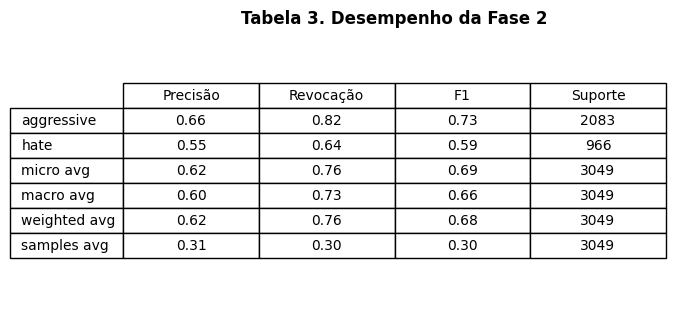

In [19]:
def relatorio_df(y_true, y_pred, nomes):
    rep = classification_report(y_true, y_pred, target_names=nomes,
                                output_dict=True, zero_division=0)
    acc = rep.pop('accuracy', None)
    df = pd.DataFrame(rep).T.rename(columns={'precision': 'Precisão', 'recall': 'Revocação',
                                             'f1-score': 'F1', 'support': 'Suporte'})
    if acc is not None:   # só existe quando o rótulo é único (Fase 1)
        df.loc['Acurácia global'] = [np.nan, np.nan, acc, df.loc['macro avg', 'Suporte']]
    return df

def estilizar(df, titulo):
    return (df.style.set_caption(titulo)
              .format({'Precisão': '{:.2f}', 'Revocação': '{:.2f}', 'F1': '{:.2f}',
                       'Suporte': '{:.0f}'}, na_rep='–')
              .background_gradient(cmap='Blues', subset=['Precisão', 'Revocação', 'F1'], vmin=0, vmax=1))

def salvar_tabela_png(df, titulo, caminho):
    txt = df.copy().astype(object)
    for c in ['Precisão', 'Revocação', 'F1']:
        txt[c] = df[c].map(lambda v: '–' if pd.isna(v) else f'{v:.2f}')
    txt['Suporte'] = df['Suporte'].map(lambda v: '–' if pd.isna(v) else f'{int(v)}')
    fig, ax = plt.subplots(figsize=(7, 0.45 * (len(txt) + 2)))
    ax.axis('off')
    tab = ax.table(cellText=txt.values, rowLabels=txt.index, colLabels=txt.columns,
                   loc='center', cellLoc='center')
    tab.auto_set_font_size(False); tab.set_fontsize(10); tab.scale(1, 1.5)
    ax.set_title(titulo, fontweight='bold')
    fig.savefig(caminho, dpi=300, bbox_inches='tight')
    plt.show()

# Uso
df_fase1 = relatorio_df(y_test, y_pred_svm_otimizado, ['Benigno', 'Crime'])
df_fase2 = relatorio_df(y_true_fase2, y_pred_fase2, colunas_crimes)
display(estilizar(df_fase1, f'Tabela 2. Desempenho da Fase 1 (SVM, limiar {limiar_svm_calibrado:.0%})'))
display(estilizar(df_fase2, 'Tabela 3. Desempenho da Fase 2 (BERTimbau)'))
salvar_tabela_png(df_fase2, 'Tabela 3. Desempenho da Fase 2', 'tabela3.png')

## Exportar resultados

Grava as previsões da cascata (teste completo, ponta a ponta) para o Notebook 3. Para persistir entre sessões do Colab, aponte `PASTA_RESULTADOS` para uma pasta do Google Drive.

In [20]:
import os
PASTA_RESULTADOS = "resultados"
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

y_true_total = df_binary_test_cleaned[colunas_crimes].values.astype(int)
pred_bert_total = np.zeros_like(y_true_total)
pred_bert_total[indices_suspeitos_teste] = y_pred_fase2      # barrado pelo SVM = 0

np.savez_compressed(f"{PASTA_RESULTADOS}/cascata_2rotulos.npz",
                    y_true_total=y_true_total, pred_bert_total=pred_bert_total,
                    probabilidade_crime_svm=probabilidade_crime_svm,
                    limiar_svm_calibrado=limiar_svm_calibrado)
print("Resultados salvos em", f"{PASTA_RESULTADOS}/cascata_2rotulos.npz")

Resultados salvos em resultados/cascata_2rotulos.npz
